# Практическая работа 4 (Прошлая работа. Нужна для подготовки 5 практической)

Ниже будет 5 практическая работа

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    'titanic.csv',
    encoding='utf-8'
)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
y = df['Survived']
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [4]:
X = df[['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']]
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


In [5]:
X.isnull().sum()

Pclass      0
Age       177
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64

In [6]:
median_age = df['Age'].median()
median_age

np.float64(28.0)

In [7]:
X['Age'] = X['Age'].fillna(median_age)

In [8]:
X.isnull().sum()

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64

In [9]:
X['Sex'] = X['Sex'].map({
    'male': 0,
    'female': 1
})

X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,0,7.2500,1,0
1,1,38.0,1,71.2833,1,0
2,3,26.0,1,7.9250,0,0
3,1,35.0,1,53.1000,1,0
4,3,35.0,0,8.0500,0,0


In [10]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  891 non-null    int64  
 1   Age     891 non-null    float64
 2   Sex     891 non-null    int64  
 3   Fare    891 non-null    float64
 4   SibSp   891 non-null    int64  
 5   Parch   891 non-null    int64  
dtypes: float64(2), int64(4)
memory usage: 41.9 KB


In [11]:
X.isnull().sum()

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 6)
X_test: (179, 6)
y_train: (712,)
y_test: (179,)


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
X_train_scaled.shape

(712, 6)

In [17]:
X_test_scaled.shape

(179, 6)

# Практическая работа 5

In [18]:
merged = X.copy()
merged['Survived'] = y.copy()

merged.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


In [19]:
merged.columns.tolist()

['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

In [20]:
merged.dtypes

Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

In [21]:
merged.isnull().sum()

Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64

In [22]:
merged.corr().round(2)

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


4.	Определите признак с наиболее сильной положительной корреляцией с Survived

Sex и частично Fare

5.	Определите признак с наиболее сильной отрицательной корреляцией с Survived

Pclass

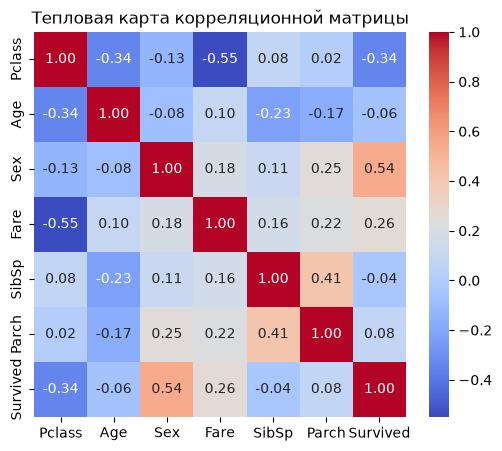

In [23]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(merged.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Тепловая карта корреляционной матрицы')
plt.show()

Какие признаки, по вашему мнению, могут быть наиболее полезны для предсказания Survived?

Я предполагаю, что Sex, Fare и возможно Pclass. Но в Pclass, я не уверен, просто предполагаю, что даже отрицательная корреляция может подсказать целевую перменную

Можно ли выбирать признаки для модели машинного обучения только на основании корреляции?

Думаю, что да

# Практическая работа 6

In [25]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

**Почему в обучении используются X_train_scaled и y_train, а не тестовые данные?**

Потому что мы только обучаем модель, а не тестируем. Зачем модели находить закономерности на данных, которая она не должна была раньше видеть?

In [27]:
y_pred_lr = model_lr.predict(X_test_scaled)

print('Первые предсказания:', y_pred_lr[:10])
print('Правильные ответы:', y_test.iloc[:10].tolist())

Первые предсказания: [0 0 0 1 1 1 1 0 1 1]
Правильные ответы: [1, 0, 0, 1, 1, 1, 1, 0, 1, 1]


**Сравните первые 10 предсказаний с правильными ответами. Найдите хотя бы один совпавший ответ и, если есть, один ошибочный. Объясните, что означает 0 и 1**

Все ответы совпали кроме первого. 0 - мёртвый, 1 - живой

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr))
print('Recall:', recall_score(y_test, y_pred_lr))
print('F1:', f1_score(y_test, y_pred_lr))
print('Confusion_matrix:', confusion_matrix(y_test, y_pred_lr))
print('Classification_report:', classification_report(y_test, y_pred_lr))

Accuracy: 0.7988826815642458
Precision: 0.7794117647058824
Recall: 0.7162162162162162
F1: 0.7464788732394366
Confusion_matrix: [[90 15]
 [21 53]]
Classification_report:               precision    recall  f1-score   support

           0       0.81      0.86      0.83       105
           1       0.78      0.72      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



Доля правильных предсказаний ~80% (accuracy)

Метрика recall показывает насколько модель находит выживших

Ложноположительное предсказание - когда модель посчитала человека живым, но он оказался мёртв
Ложноотрицательные предсказания - когда модель посчитала человека мёртвым, но он оказался живым

In [33]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred_tree))
print('Precision:', precision_score(y_test, y_pred_tree))
print('Recall:', recall_score(y_test, y_pred_tree))
print('F1:', f1_score(y_test, y_pred_tree))
print('Confusion_matrix:', confusion_matrix(y_test, y_pred_tree))
print('Classification_report:', classification_report(y_test, y_pred_tree))

Accuracy: 0.7988826815642458
Precision: 0.796875
Recall: 0.6891891891891891
F1: 0.7391304347826086
Confusion_matrix: [[92 13]
 [23 51]]
Classification_report:               precision    recall  f1-score   support

           0       0.80      0.88      0.84       105
           1       0.80      0.69      0.74        74

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



**Вывод:** DecisionTreeClassifier угадывает чаще чем LogisticRegression

**какой признак имел наиболее сильную положительную корреляцию с Survived в вашей матрице?**

Sex

**какой признак имел наиболее сильную отрицательную корреляцию?**

Pclass